# 02 · Feature menus, filters and configuration

This notebook prepares everything the training steps need. It trains no model.

1. It loads the Elliptic++ transactions and the 27 graph features of step 01, and checks them.
2. It cleans the economic columns of Elliptic++ (family D).
3. It adds the labels, the split and the evaluation rows.
4. It removes **redundant** transparent features (near-copies of an earlier feature), with a guard for the illicit class.
5. It removes from the menu `local_agg_graph` the original features that are near-copies of a graph feature.
6. It draws the **correlation plots** that explain every removal (for the report).
7. It writes an **audit** of every feature and chooses, column by column, how each model sees it (the transformation rule).
8. It writes one **complete dataset** with the raw values, the edges, and a **configuration file** read by every later step.

**Feature families**

| Family | Columns | Meaning | Source |
|---|---|---|---|
| LF | 93 | Local features of Elliptic (anonymous) | `txs_features.csv` |
| AF | 72 | Aggregate features of Elliptic (anonymous, summaries of the neighbours) | `txs_features.csv` |
| A | 8 | how many links the transaction has | step 01 |
| B | 12 | which position it holds in the money flow of its time step | step 01 |
| C | 7 | which shape its neighbourhood has | step 01 |
| D | 14 (17 in the file) | economic data of the transaction | the extra columns of Elliptic++ |

LF and AF are called **opaque** (nobody knows what they mean), A, B, C and D **transparent**.

**Input** (on Google Drive): `txs_features.csv`, `txs_classes.csv`, `txs_edgelist.csv` in `DATA_PATH`; `A_features.csv`, `B_features.csv`, `C_features.csv` in `DATA_PATH/01-graph-feature-extractions/`.

**Output**

| File | Content |
|---|---|
| `02-feature-menus/dataset.parquet` | one row per transaction (203,769, same order as `txs_features.csv`): service columns (`txId`, `time_step`, `split`, `y`, `in_eval`, `has_econ`) and the **raw** values of all 206 features, as 32-bit floats |
| `02-feature-menus/edges.parquet` | the 234,355 edges as row numbers of the dataset (`src_row` → `dst_row`, the direction of the money) and their time step |
| `02-feature-menus/config.json` | every decision the later steps need: menus, removed columns, split, labels, seeds, models and search spaces, training and evaluation settings, transformations. No result |
| `02-feature-menus/feature_audit.csv` | one row per feature: distribution on the train time steps, univariate ROC-AUC, chosen transformation |
| `02-feature-menus/removed_features.csv` | every removed column: why, which column was kept instead, the correlations |
| `plots/02_corr_*.png` | the three correlation plots |

**Labels.** Only the labels of the train time steps (1–30) are used, in two places: the class guard of the redundancy filter and the audit. Validation and test labels are only counted.

**How to run it.** A CPU runtime is enough. `Runtime → Run all`. Every output that already exists on Drive is skipped; set `FORCE_RECOMPUTE = True` (section 0) to write everything again. **Run time:** about 10 minutes, mostly to read the 700 MB of `txs_features.csv`.

## 0. Setup

In [ ]:
# Install the libraries that Colab does not have by default (only if they are missing).
import importlib.util
import subprocess
import sys

for package, module in [('pyarrow', 'pyarrow')]:   # pandas needs it to write Parquet files
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

In [ ]:
# Connect Google Drive: every input and output of the project lives in DATA_PATH.
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

DATA_PATH = Path('/content/drive/MyDrive/UNIVERSITA/block-crypto/data')
FEATURE_DIR = DATA_PATH / '01-graph-feature-extractions'   # input: the graph features of step 01
OUT_DIR = DATA_PATH / '02-feature-menus'                    # output of this notebook
PLOT_DIR = DATA_PATH / 'plots'                              # plots of every step, prefixed with the step number
LOCAL_INPUT = Path('/content/input')                        # local copy of the input files

Mounted at /content/drive


In [ ]:
# Copy the input files from Drive to the Colab disk: reading a local file is much faster.
# The outputs are never copied: they are always written directly on Drive.
import shutil

INPUTS = {name: DATA_PATH / name for name in ['txs_features.csv', 'txs_classes.csv', 'txs_edgelist.csv']}
INPUTS.update({name: FEATURE_DIR / name for name in ['A_features.csv', 'B_features.csv', 'C_features.csv']})

LOCAL_INPUT.mkdir(exist_ok=True)
INPUT_FILES = {}
for name, source in INPUTS.items():
    assert source.exists(), f'{source} is missing: run the previous steps first'
    target = LOCAL_INPUT / name
    if not target.exists() or target.stat().st_size != source.stat().st_size:
        shutil.copy(source, target)
    INPUT_FILES[name] = target
    print(f'{name}: {target.stat().st_size / 1e6:,.0f} MB')

txs_features.csv: 695 MB
txs_classes.csv: 2 MB
txs_edgelist.csv: 4 MB
A_features.csv: 5 MB
B_features.csv: 25 MB
C_features.csv: 8 MB


In [ ]:
import json
import os
import time
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from PIL import Image

# Split by time step (no shuffling: the model is always tested on the future).
TRAIN_STEPS, VAL_STEPS, TEST_STEPS = range(1, 31), range(31, 41), range(41, 50)

RHO_MAX = 0.95    # redundancy filter: |Spearman rho| above this, in every group, means "near-copy"
SKEW_MAX = 2.0    # transformation rule: columns with |skewness| above this get a log before the z-score
TUNING_SEED, FINAL_SEEDS = 42, [0, 1, 2]
CONFIG_VERSION = 1

# True = delete the outputs of this notebook on Drive and write them again.
FORCE_RECOMPUTE = False

OUTPUTS = {name: OUT_DIR / name for name in
           ['dataset.parquet', 'edges.parquet', 'config.json', 'feature_audit.csv', 'removed_features.csv']}
PLOTS = {name: PLOT_DIR / name for name in
         ['02_corr_transparent.png', '02_corr_removed.png', '02_corr_transparent_vs_opaque.png']}
if FORCE_RECOMPUTE:
    for path in [*OUTPUTS.values(), *PLOTS.values()]:
        path.unlink(missing_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
# The columns of every family, in the order of the redundancy filter (the first of two near-copies is kept).
LF_COLUMNS = [f'Local_feature_{i}' for i in range(1, 94)]
AF_COLUMNS = [f'Aggregate_feature_{i}' for i in range(1, 73)]
A_COLUMNS = ['in_deg', 'out_deg', 'anc2', 'desc2', 'pred_out_mean', 'pred_out_max', 'succ_in_mean', 'succ_in_max']
B_COLUMNS = ['pr_fwd', 'pr_rev', 'betw', 'harm_in', 'harm_out', 'eig', 'hub', 'auth', 'core', 'katz_in', 'katz_out', 'clo']
C_COLUMNS = ['is_fan_in', 'is_fan_out', 'chain_len', 'diam_out', 'diam_in', 'orc_mean', 'orc_min']
# D: the totals first, because they are the easiest to explain; then counts, then the input and output statistics.
D_COLUMNS = ['in_BTC_total', 'out_BTC_total', 'fees', 'size', 'num_input_addresses', 'num_output_addresses',
             'in_BTC_min', 'in_BTC_max', 'in_BTC_mean', 'in_BTC_median',
             'out_BTC_min', 'out_BTC_max', 'out_BTC_mean', 'out_BTC_median']
# Three extra columns of Elliptic++ are exact copies of other columns and are not kept (checked in section 3).
D_COPIES = {'total_BTC': 'out_BTC_total', 'in_txs_degree': 'in_deg', 'out_txs_degree': 'out_deg'}

FAMILIES = {'LF': LF_COLUMNS, 'AF': AF_COLUMNS, 'A': A_COLUMNS, 'B': B_COLUMNS, 'C': C_COLUMNS, 'D': D_COLUMNS}
FAMILY_OF = {col: family for family, columns in FAMILIES.items() for col in columns}
OPAQUE = LF_COLUMNS + AF_COLUMNS
GRAPH = A_COLUMNS + B_COLUMNS + C_COLUMNS
TRANSPARENT = GRAPH + D_COLUMNS
ALL_FEATURES = OPAQUE + TRANSPARENT
SERVICE_COLUMNS = ['txId', 'time_step', 'split', 'y', 'in_eval', 'has_econ']
assert len(ALL_FEATURES) == len(set(ALL_FEATURES)) == 206

In [ ]:
def atomic(path, write):
    """Write through a temporary file, then rename it: a run that stops while writing
    never leaves a half-written file on Drive."""
    tmp = path.with_name(path.name + '.tmp')
    write(tmp)
    os.replace(tmp, path)


def to_builtin(value):
    """Make NumPy numbers JSON-serializable."""
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    raise TypeError(f'not JSON-serializable: {type(value)}')


def write_csv(df, path):
    atomic(path, lambda tmp: df.to_csv(tmp, index=False, float_format='%.10g'))


def write_parquet(df, path):
    atomic(path, lambda tmp: df.to_parquet(tmp, index=False))


def write_json(obj, path):
    text = json.dumps(obj, indent=1, default=to_builtin, allow_nan=False, ensure_ascii=False)
    atomic(path, lambda tmp: tmp.write_text(text, encoding='utf-8'))


def already_done(path):
    if path.exists():
        print(f'{path.name} is already on Drive: skipped.')
        return True
    return False


def fmt_time(seconds):
    """Format a duration as '12.3s' or '4m 05s'."""
    if seconds < 60:
        return f'{seconds:.1f}s'
    minutes, seconds = divmod(int(seconds), 60)
    return f'{minutes}m {seconds:02d}s'

### The three rules of this notebook

**Spearman correlation.** For two columns $x$ and $y$ on the same rows,

$$\rho(x, y) = \operatorname{corr}\big(\operatorname{rank}(x),\ \operatorname{rank}(y)\big),$$

the Pearson correlation of the ranks (tied values share their average rank). It measures whether two columns put the transactions in the same **order**, whatever their scale: $|\rho| = 1$ means one column is a monotone function of the other. A constant column has no order: its $\rho$ is set to 0.

**Redundancy filter with a class guard.** Three groups of rows are used:
- *all*: every node of the train time steps 1–30 with the Elliptic++ data (unknown nodes included);
- *illicit* and *licit*: the evaluation rows of the train time steps, by class.

The columns are visited in a fixed order $c_1, c_2, \dots$ Column $c_j$ is **removed** if a column $c_i$ that was already kept satisfies

$$\min\Big(\,|\rho_{\text{all}}(c_i, c_j)|,\ |\rho_{\text{illicit}}(c_i, c_j)|,\ |\rho_{\text{licit}}(c_i, c_j)|\,\Big) > 0.95 .$$

Why three groups: only 2.4% of the train nodes are illicit, so $\rho_{\text{all}}$ is decided by the other nodes. Two columns could be copies for most nodes but differ exactly on the illicit ones; the guard keeps them in that case. Only train labels are used, so nothing leaks from validation or test.

**Transformation rule** (profile `scaled`, used by Logistic Regression, MLP and GNNs; Random Forest and XGBoost use the raw values, because trees only use the order of the values). For each column, on the nodes of the train time steps:

| Column | Transformation |
|---|---|
| binary (only the values 0 and 1) | unchanged |
| never negative, skewness $> 2$ | $\log(1 + x)$, then z-score |
| with negative values, $\lvert\text{skewness}\rvert > 2$ | $\operatorname{sign}(x)\,\log(1 + \lvert x \rvert)$, then z-score |
| otherwise | z-score |

with the z-score $z = (t - \mu)/\sigma$, where $t$ is the value after the log (if any) and $\mu$, $\sigma$ are the mean and the standard deviation **of that column** over all nodes of the time steps 1–30 (unknown nodes included). The same $\mu$, $\sigma$ are used for validation and test. The skewness is the usual adjusted moment coefficient $\frac{n}{(n-1)(n-2)} \sum_v \left(\frac{x_v - \bar x}{s}\right)^3$. Note that $\operatorname{sign}(x)\log(1+|x|) = \log(1+x)$ when $x \ge 0$: one function covers both log rows, and it stays defined if a negative value appears later.

In [ ]:
def standardized_ranks(df):
    """Ranks of every column, centred and divided by their norm, so that a dot product of two columns is
    their Spearman rho. A constant column becomes all zeros (rho = 0 with everything)."""
    out = np.empty(df.shape, dtype=np.float64)
    for k, col in enumerate(df.columns):
        r = df[col].rank().to_numpy(np.float64)
        r -= r.mean()
        norm = np.sqrt(r @ r)
        out[:, k] = r / norm if norm > 0 else 0.0
    return out


def spearman(left, right=None):
    """Spearman rho between the columns of `left` and those of `right` (same rows); `right=None`: left with itself."""
    a = standardized_ranks(left)
    b = a if right is None else standardized_ranks(right)
    rho = np.clip(a.T @ b, -1.0, 1.0)
    return pd.DataFrame(rho, index=left.columns, columns=left.columns if right is None else right.columns)


def group_rho(table, left, right, groups):
    """{group name: Spearman rho between the columns `left` and `right`, on the rows of that group}."""
    return {g: spearman(table[left].iloc[rows], None if right is None else table[right].iloc[rows])
            for g, rows in groups.items()}


def redundancy_filter(table, order, groups, threshold):
    """Walk the columns in `order`; remove a column when, in every group, |rho| > threshold with a kept column.
    Returns the kept columns, the removed ones (with the kept partner and the rho of each group), and the rho."""
    rho = group_rho(table, order, None, groups)
    kept, removed = [], []
    for col in order:
        if kept:
            guard = pd.concat([rho[g].loc[col, kept].abs() for g in groups], axis=1).min(axis=1)
            if guard.max() > threshold:
                partner = guard.idxmax()
                removed.append({'column': col, 'kept_partner': partner,
                                **{f'rho_{g}': float(rho[g].loc[col, partner]) for g in groups}})
                continue
        kept.append(col)
    return kept, removed, rho


def cross_filter(rho, threshold):
    """Columns of `rho` (opaque) that are near-copies, in every group, of one of its rows (transparent)."""
    first = next(iter(rho.values()))
    guard = pd.DataFrame(np.minimum.reduce([r.abs().to_numpy() for r in rho.values()]),
                         index=first.index, columns=first.columns)
    removed = []
    for col in guard.columns:
        if guard[col].max() > threshold:
            partner = guard[col].idxmax()
            removed.append({'column': col, 'kept_partner': partner,
                            **{f'rho_{g}': float(r.loc[partner, col]) for g, r in rho.items()}})
    return removed


def constant_columns(df, rows=None):
    """Columns with a single value (on `rows`, if given)."""
    return [col for col in df.columns if (df[col] if rows is None else df[col].iloc[rows]).nunique() <= 1]


def choose_transform(values, skew_max=SKEW_MAX):
    """The transformation of the profile `scaled` for one column (values on the train time steps)."""
    v = np.asarray(values, dtype=np.float64)
    unique = np.unique(v)
    if len(unique) == 2 and set(unique) <= {0.0, 1.0}:
        return 'binary', 'only the values 0 and 1: unchanged'
    skew = float(pd.Series(v).skew())
    if v.min() >= 0 and skew > skew_max:
        return 'log1p+z', f'never negative, skewness {skew:.1f} > {skew_max:g}: log(1 + x), then z-score'
    if v.min() < 0 and abs(skew) > skew_max:
        return 'signed_log1p+z', (f'negative values, |skewness| {abs(skew):.1f} > {skew_max:g}: '
                                  'sign(x) log(1 + |x|), then z-score')
    return 'z', f'skewness {skew:.1f}: z-score only'


def log_part(values, transform):
    """The value before the z-score: sign(x) log(1 + |x|) for the two log transformations, x otherwise."""
    x = np.asarray(values, dtype=np.float64)
    return np.sign(x) * np.log1p(np.abs(x)) if transform in ('log1p+z', 'signed_log1p+z') else x


def fit_scaler(values, transform):
    """(mu, sigma) of the z-score; a binary column keeps (0, 1), i.e. it is not changed."""
    if transform == 'binary':
        return 0.0, 1.0
    t = log_part(values, transform)
    return float(t.mean()), float(t.std())


def scale(values, spec):
    """Apply one column of config['transforms']['profiles']['scaled']['columns'] to raw values."""
    return (log_part(values, spec['transform']) - spec['mean']) / spec['std']

## 1. Test on a toy table

Before touching the real data, the three rules run on a small synthetic table where the right answer is known (3% of the rows are "illicit"):

| Column | How it is made | Expected |
|---|---|---|
| `a` | random, long right tail | kept |
| `b` | `a` × (1 + tiny noise): a copy for every row | **removed**, near-copy of `a` |
| `c` | equal to `a`, except on the illicit rows, where it is random | **kept** by the class guard: $\rho_{\text{all}} > 0.95$ but $\rho_{\text{illicit}}$ is low |
| `d` | independent, symmetric | kept; z-score only |
| `e` | binary flag | kept; unchanged |
| `f` | never negative, long right tail | kept; log, then z-score |
| `g` | `f`-like minus 2, so with negative values | kept; signed log, then z-score |
| `h` | constant | removed as constant |

In [ ]:
rng = np.random.default_rng(0)
n = 4000
toy_y = (rng.random(n) < 0.03).astype(int)
a = rng.lognormal(size=n)
toy = pd.DataFrame({
    'a': a,
    'b': a * (1 + 1e-3 * rng.standard_normal(n)),
    'c': np.where(toy_y == 1, rng.lognormal(size=n), a),
    'd': rng.standard_normal(n),
    'e': (rng.random(n) < 0.2).astype(float),
    'f': rng.lognormal(sigma=1.5, size=n),
    'g': rng.lognormal(sigma=1.5, size=n) - 2,
    'h': np.ones(n),
})
toy_groups = {'all': np.arange(n), 'illicit': np.flatnonzero(toy_y == 1), 'licit': np.flatnonzero(toy_y == 0)}

assert constant_columns(toy) == ['h']
toy_order = [col for col in toy.columns if col != 'h']
kept, removed, toy_rho = redundancy_filter(toy, toy_order, toy_groups, RHO_MAX)
# the case of column c is meaningful: a copy for the whole table, not for the illicit rows
assert toy_rho['all'].loc['a', 'c'] > RHO_MAX and abs(toy_rho['illicit'].loc['a', 'c']) < 0.5
assert [r['column'] for r in removed] == ['b'] and removed[0]['kept_partner'] == 'a'
assert kept == ['a', 'c', 'd', 'e', 'f', 'g']

# transparent a vs opaque b, d: b is a near-copy of a in every group, d is not
toy_cross = group_rho(toy, ['a'], ['b', 'd'], toy_groups)
assert [r['column'] for r in cross_filter(toy_cross, RHO_MAX)] == ['b']

expected = {'d': 'z', 'e': 'binary', 'f': 'log1p+z', 'g': 'signed_log1p+z'}
for col, transform in expected.items():
    got, reason = choose_transform(toy[col])
    assert got == transform, (col, got)
    mean, std = fit_scaler(toy[col], got)
    z = scale(toy[col], {'transform': got, 'mean': mean, 'std': std})
    if got == 'binary':
        assert np.array_equal(z, toy[col])
    else:
        assert abs(z.mean()) < 1e-9 and abs(z.std() - 1) < 1e-9
    print(f'{col}: {reason}')

print(f"rho(a, c): all nodes {toy_rho['all'].loc['a', 'c']:.3f}, illicit {toy_rho['illicit'].loc['a', 'c']:.3f}"
      ' -> kept by the class guard')
print('Toy test passed.')

d: skewness 0.0: z-score only
e: only the values 0 and 1: unchanged
f: never negative, skewness 11.6 > 2: log(1 + x), then z-score
g: negative values, |skewness| 8.3 > 2: sign(x) log(1 + |x|), then z-score
rho(a, c): all nodes 0.967, illicit -0.047 -> kept by the class guard
Toy test passed.


## 2. Load and check the inputs

The checks: 203,769 transactions and 234,355 edges; the three files of step 01 have the expected columns and the same rows in the same order as `txs_features.csv`; no value is missing, except the Elliptic++ columns of 965 transactions (section 3). The economic columns are read as 64-bit floats for the checks of section 3; every feature is stored as a 32-bit float at the end.

In [ ]:
start = time.time()
header = pd.read_csv(INPUT_FILES['txs_features.csv'], nrows=0).columns.tolist()
D_RAW = header[167:]
assert header[:2] == ['txId', 'Time step'] and header[2:167] == OPAQUE, 'unexpected columns in txs_features.csv'
assert sorted(D_RAW) == sorted(D_COLUMNS + list(D_COPIES)), 'unexpected Elliptic++ columns'

dtypes = {col: np.float32 for col in OPAQUE} | {col: np.float64 for col in D_RAW}
raw = pd.read_csv(INPUT_FILES['txs_features.csv'], dtype=dtypes).rename(columns={'Time step': 'time_step'})
classes = pd.read_csv(INPUT_FILES['txs_classes.csv'])
edge_list = pd.read_csv(INPUT_FILES['txs_edgelist.csv'])
graph = {family: pd.read_csv(INPUT_FILES[f'{family}_features.csv']) for family in 'ABC'}
print(f'Inputs read in {fmt_time(time.time() - start)}.')

N = len(raw)
TXID = raw['txId'].to_numpy()
STEP = raw['time_step'].to_numpy()
assert N == 203_769 and raw['txId'].is_unique and len(edge_list) == 234_355
assert set(STEP) == set(range(1, 50))
for family, columns in [('A', A_COLUMNS), ('B', B_COLUMNS), ('C', C_COLUMNS)]:
    df = graph[family]
    assert list(df.columns) == ['txId'] + columns, f'{family}_features.csv: unexpected columns'
    assert len(df) == N and (df['txId'].to_numpy() == TXID).all(), f'{family}_features.csv: rows missing or in another order'
    assert not df.isna().any().any() and np.isfinite(df[columns].to_numpy(np.float64)).all()
assert not raw[['txId', 'time_step'] + OPAQUE].isna().any().any()
print(f'{N:,} transactions, {len(edge_list):,} edges, {len(OPAQUE)} opaque + {len(GRAPH)} graph features: all checks passed.')

Inputs read in 21.5s.
203,769 transactions, 234,355 edges, 165 opaque + 27 graph features: all checks passed.


## 3. Clean the economic columns (family D)

Elliptic++ adds 17 columns. Three are exact copies of other columns and are dropped, after checking that they really are copies:
- `total_BTC` = `out_BTC_total`;
- `in_txs_degree` = `in_deg` and `out_txs_degree` = `out_deg` (family A: the number of incoming and outgoing edges).

One relation is checked and documented, but the column stays, because the fee is meaningful on its own:

$$\texttt{fees} = \texttt{in\_BTC\_total} - \texttt{out\_BTC\_total}.$$

The Elliptic++ columns are missing for **965 transactions** (always all together; 519 of them are labeled, none is illicit). These rows stay in the graph, because their neighbours need them, but:
- `has_econ = False` marks them, and they are excluded from loss and metrics (`in_eval = False`, section 4);
- their D values are filled with the **median of the nodes of the train time steps** that have the data, so that they are valid inputs for their neighbours.

In [ ]:
missing = raw[D_RAW].isna()
assert missing.eq(missing.iloc[:, 0], axis=0).all().all(), 'the Elliptic++ columns are not missing on the same rows'
HAS_ECON = ~missing.iloc[:, 0].to_numpy()
IN_TRAIN = np.isin(STEP, TRAIN_STEPS)
assert (~HAS_ECON).sum() == 965

econ = raw.loc[HAS_ECON]
assert np.allclose(econ['total_BTC'], econ['out_BTC_total'], rtol=1e-12, atol=0), 'total_BTC is not a copy of out_BTC_total'
assert (econ['in_txs_degree'].to_numpy() == graph['A'].loc[HAS_ECON, 'in_deg'].to_numpy()).all()
assert (econ['out_txs_degree'].to_numpy() == graph['A'].loc[HAS_ECON, 'out_deg'].to_numpy()).all()
fee_error = np.max(np.abs(econ['in_BTC_total'] - econ['out_BTC_total'] - econ['fees'])
                   / np.maximum(econ['in_BTC_total'], 1e-12))
assert fee_error < 1e-6, f'fees != in_BTC_total - out_BTC_total (relative error {fee_error:.1e})'
print(f'Exact copies confirmed: {", ".join(f"{k} = {v}" for k, v in D_COPIES.items())}. '
      f'fees = in_BTC_total - out_BTC_total (largest relative error {fee_error:.1e}).')

D_MEDIANS = raw.loc[HAS_ECON & IN_TRAIN, D_COLUMNS].median()
D = raw[D_COLUMNS].fillna(D_MEDIANS)
print(f'{(~HAS_ECON).sum()} rows without Elliptic++ data: D filled with the train medians.')

Exact copies confirmed: total_BTC = out_BTC_total, in_txs_degree = in_deg, out_txs_degree = out_deg. fees = in_BTC_total - out_BTC_total (largest relative error 2.3e-16).
965 rows without Elliptic++ data: D filled with the train medians.


## 4. Labels, split and evaluation rows

- `y`: 1 = illicit (the positive class), 0 = licit, empty = unknown (class 1, 2 and 3 of `txs_classes.csv`). The unknown nodes stay in the graph but never enter a loss or a metric.
- `split`: `train` (time steps 1–30), `val` (31–40), `test` (41–49).
- `in_eval`: the row enters loss and metrics: it is labeled **and** has the Elliptic++ data.

The class weight of the neural models is computed on the evaluation rows of the train:

$$w_+ = \frac{\#\{\text{licit}\}}{\#\{\text{illicit}\}} .$$

The counts below are known from the exploration of the data and are checked exactly.

In [ ]:
cls = raw[['txId']].merge(classes, on='txId', how='left', validate='one_to_one')['class']
assert cls.notna().all() and set(cls.unique()) <= {1, 2, 3}, 'unexpected labels in txs_classes.csv'
Y = cls.map({1: 1, 2: 0}).astype('Int8')   # unknown -> <NA>
assert not (Y[~HAS_ECON] == 1).any(), 'an illicit transaction has no Elliptic++ data'

SPLIT = np.select([np.isin(STEP, TRAIN_STEPS), np.isin(STEP, VAL_STEPS), np.isin(STEP, TEST_STEPS)],
                  ['train', 'val', 'test'], default='')
assert (SPLIT != '').all()
IN_EVAL = Y.notna().to_numpy() & HAS_ECON
IS_ILLICIT = (Y == 1).fillna(False).to_numpy(dtype=bool)

counts = pd.DataFrame({
    split: {'nodes': int((SPLIT == split).sum()),
            'labeled': int((Y.notna().to_numpy() & (SPLIT == split)).sum()),
            'eval_rows': int((IN_EVAL & (SPLIT == split)).sum()),
            'illicit': int((IN_EVAL & IS_ILLICIT & (SPLIT == split)).sum())}
    for split in ['train', 'val', 'test']}).T
counts['licit'] = counts['eval_rows'] - counts['illicit']
counts['prevalence'] = counts['illicit'] / counts['eval_rows']
display(counts.round(4))

EXPECTED = {'train': (123_287, 26_750, 2_954), 'val': (38_316, 9_429, 1_067), 'test': (42_166, 9_866, 524)}
for split, (nodes, eval_rows, illicit) in EXPECTED.items():
    assert tuple(counts.loc[split, ['nodes', 'eval_rows', 'illicit']]) == (nodes, eval_rows, illicit), split
POS_WEIGHT = counts.loc['train', 'licit'] / counts.loc['train', 'illicit']
print(f'pos_weight = {counts.loc["train", "licit"]:,} / {counts.loc["train", "illicit"]:,} = {POS_WEIGHT:.4f}')

,nodes,labeled,eval_rows,illicit,licit,prevalence
train,123287,26905,26750,2954,23796,0.1104
val,38316,9686,9429,1067,8362,0.1132
test,42166,9973,9866,524,9342,0.0531


pos_weight = 23,796 / 2,954 = 8.0555


In [ ]:
# The complete feature table, in the row order of txs_features.csv (row number = node id).
features = pd.concat([raw[OPAQUE], *(graph[f][cols] for f, cols in [('A', A_COLUMNS), ('B', B_COLUMNS), ('C', C_COLUMNS)]), D],
                     axis=1)
assert list(features.columns) == ALL_FEATURES and len(features) == N
del raw, econ   # free memory: everything needed is in `features`, TXID, STEP, Y, HAS_ECON

TRAIN_ROWS = np.flatnonzero(IN_TRAIN)                      # every node of time steps 1-30
TRAIN_ECON = np.flatnonzero(IN_TRAIN & HAS_ECON)           # ... with the Elliptic++ data
GROUPS = {'all': TRAIN_ECON,
          'illicit': np.flatnonzero(IN_TRAIN & IN_EVAL & IS_ILLICIT),
          'licit': np.flatnonzero(IN_TRAIN & IN_EVAL & ~IS_ILLICIT)}
for g, rows in GROUPS.items():
    print(f'group {g}: {len(rows):,} rows')

group all: 122,992 rows
group illicit: 2,954 rows
group licit: 23,796 rows


## 5. Redundancy filter on the 41 transparent features

The rule of section 0, on the families A, B, C, D, visited in this order: A → B → C → D, each family in the order of step 01, and D with the totals first (`in_BTC_total`, `out_BTC_total`, `fees`, `size`, `num_input_addresses`, `num_output_addresses`, then minimum, maximum, mean and median of inputs and outputs). Of two near-copies the first is kept: the simpler or more readable one.

Every removal is written to `removed_features.csv` (and later to `config.json`), with the kept partner and the three correlations. A removed feature stays in `dataset.parquet`: only the menus leave it out.

A column that is constant on the train time steps carries no information and is removed first, from every menu.

In [ ]:
CONSTANT = constant_columns(features, TRAIN_ECON)
print('Constant on the train time steps:', CONSTANT or 'none')

order = [col for col in TRANSPARENT if col not in CONSTANT]
TRANSPARENT_KEPT, REDUNDANT, RHO_TRANSPARENT = redundancy_filter(features, order, GROUPS, RHO_MAX)

for family in ['A', 'B', 'C', 'D']:
    kept = [c for c in TRANSPARENT_KEPT if FAMILY_OF[c] == family]
    print(f'{family}: {len(FAMILIES[family])} -> {len(kept)} columns')
print(f'Transparent features: {len(TRANSPARENT)} -> {len(TRANSPARENT_KEPT)}.')
display(pd.DataFrame(REDUNDANT).round(4) if REDUNDANT else 'No redundant column.')

Constant on the train time steps: none
A: 8 -> 6 columns
B: 12 -> 11 columns
C: 7 -> 7 columns
D: 14 -> 9 columns
Transparent features: 41 -> 33.


,column,kept_partner,rho_all,rho_illicit,rho_licit
0,pred_out_max,pred_out_mean,0.9941,0.9969,0.9822
1,succ_in_max,succ_in_mean,0.9980,0.9983,0.9957
2,katz_in,harm_in,0.9691,0.9937,0.9890
3,out_BTC_total,in_BTC_total,1.0000,1.0000,1.0000
4,in_BTC_max,in_BTC_total,0.9913,0.9923,0.9834
5,in_BTC_mean,in_BTC_total,0.9702,0.9640,0.9509
6,out_BTC_max,in_BTC_total,0.9957,0.9969,0.9938
7,out_BTC_mean,in_BTC_total,0.9805,0.9848,0.9758


## 6. Transparent against opaque features (menu `local_agg_graph`)

The menu `local_agg_graph` puts the 165 original features next to the graph features A, B, C (it has no D). If an original (opaque) column is a near-copy of a kept graph feature, with the same rule and the same three groups, the opaque one is removed **from this menu only**: the transparent one explains the same information. The menus `local` and `local_agg` stay intact, because they are the reference of the literature.

The same correlations, for all 41 transparent features, go into the third plot: how similar is each of them to the most similar original feature?

In [ ]:
opaque = [col for col in OPAQUE if col not in CONSTANT]
transparent_all = [col for col in TRANSPARENT if col not in CONSTANT]
RHO_TO_OPAQUE = group_rho(features, transparent_all, opaque, GROUPS)

GRAPH_KEPT = [col for col in TRANSPARENT_KEPT if col in GRAPH]
OPAQUE_REMOVED = cross_filter({g: r.loc[GRAPH_KEPT] for g, r in RHO_TO_OPAQUE.items()}, RHO_MAX)
print(f'Opaque columns removed from local_agg_graph: {len(OPAQUE_REMOVED)}')
display(pd.DataFrame(OPAQUE_REMOVED).round(4) if OPAQUE_REMOVED else 'None.')

closest = RHO_TO_OPAQUE['all'].abs().idxmax(axis=1)
SIMILARITY = pd.DataFrame({
    'family': [FAMILY_OF[c] for c in transparent_all],
    'closest_opaque': closest,
    'abs_rho_all': [abs(RHO_TO_OPAQUE['all'].loc[c, o]) for c, o in closest.items()],
    'abs_rho_illicit': [abs(RHO_TO_OPAQUE['illicit'].loc[c, o]) for c, o in closest.items()],
}, index=transparent_all)
display(SIMILARITY.groupby('family')[['abs_rho_all', 'abs_rho_illicit']].max().round(3))

Opaque columns removed from local_agg_graph: 0


'None.'

,abs_rho_all,abs_rho_illicit
family,,
A,0.374,0.497
B,0.555,0.602
C,0.432,0.490
D,1.000,1.000


In [ ]:
removed_rows = [{'column': col, 'family': 'D', 'rule': 'exact copy', 'scope': 'not in the dataset', 'kept_partner': kept}
                for col, kept in D_COPIES.items()]
removed_rows += [{'column': col, 'family': FAMILY_OF[col], 'rule': 'constant on the train time steps',
                  'scope': 'every menu'} for col in CONSTANT]
removed_rows += [{**r, 'family': FAMILY_OF[r['column']], 'rule': f'near-copy (|rho| > {RHO_MAX} in every group)',
                  'scope': 'every menu'} for r in REDUNDANT]
removed_rows += [{**r, 'family': FAMILY_OF[r['column']], 'rule': f'near-copy of a graph feature (|rho| > {RHO_MAX} in every group)',
                  'scope': 'local_agg_graph'} for r in OPAQUE_REMOVED]
REMOVED = pd.DataFrame(removed_rows, columns=['column', 'family', 'rule', 'scope', 'kept_partner',
                                              'rho_all', 'rho_illicit', 'rho_licit'])
if not already_done(OUTPUTS['removed_features.csv']):
    write_csv(REMOVED, OUTPUTS['removed_features.csv'])
    print(f'removed_features.csv written ({len(REMOVED)} rows).')

removed_features.csv written (11 rows).


## 7. The feature menus

| Key | # | Columns | Question |
|---|---|---|---|
| `local` | 0a | LF | reference of the literature (Local features, without the time step) |
| `local_agg` | 0b | LF + AF | complete reference |
| `graph` | 1 | A + B + C, filtered | graph structure only |
| `econ` | 2 | D, filtered | economic data with a name only |
| `transparent` | 3 | A + B + C + D, filtered | everything transparent |
| `local_agg_graph` | 4 | LF + AF + A + B + C, filtered | does the structure add information to the original features? |
| `none` | 5 | none ($x = 1$, GNNs only) | what message passing gets from the graph alone |

In [ ]:
def kept_of(families):
    return [col for col in TRANSPARENT_KEPT if FAMILY_OF[col] in families]

opaque_out = {r['column'] for r in OPAQUE_REMOVED}
MENUS = {
    'local': {'id': '0a', 'columns': [c for c in LF_COLUMNS if c not in CONSTANT],
              'description': 'Local features of Elliptic (no time step): reference of the literature'},
    'local_agg': {'id': '0b', 'columns': [c for c in OPAQUE if c not in CONSTANT],
                  'description': 'Local + Aggregate features of Elliptic: complete reference'},
    'graph': {'id': '1', 'columns': kept_of('ABC'),
              'description': 'graph structure only: families A, B, C after the redundancy filter'},
    'econ': {'id': '2', 'columns': kept_of('D'),
             'description': 'economic data of Elliptic++ only: family D after cleaning and redundancy filter'},
    'transparent': {'id': '3', 'columns': kept_of('ABCD'),
                    'description': 'every transparent feature: A, B, C, D after the redundancy filter'},
    'local_agg_graph': {'id': '4', 'columns': [c for c in OPAQUE if c not in CONSTANT and c not in opaque_out] + kept_of('ABC'),
                        'description': 'original features plus A, B, C: does the structure add information?'},
    'none': {'id': '5', 'columns': [],
             'description': 'no feature: constant input x = 1, GNNs only; what message passing gets from the graph alone'},
}
for key, menu in MENUS.items():
    menu['n_columns'] = len(menu['columns'])
display(pd.DataFrame({k: {'id': m['id'], 'columns': m['n_columns'], 'description': m['description']}
                      for k, m in MENUS.items()}).T)

,id,columns,description
local,0a,93,Local features of Elliptic (no time step): ref...
local_agg,0b,165,Local + Aggregate features of Elliptic: comple...
graph,1,24,"graph structure only: families A, B, C after t..."
econ,2,9,economic data of Elliptic++ only: family D aft...
transparent,3,33,"every transparent feature: A, B, C, D after th..."
local_agg_graph,4,189,"original features plus A, B, C: does the struc..."
none,5,0,"no feature: constant input x = 1, GNNs only; w..."


## 8. Correlation plots

Three plots for the report, in `data/plots/` (PNG, at most 1200 × 800 pixels and 200 KB):

1. `02_corr_transparent.png`: the Spearman correlation between the 41 transparent features on all nodes of the train time steps. Blue = negative, red = positive, grey = no correlation. Removed columns are marked with ×, and the pair that removed them is outlined.
2. `02_corr_removed.png`: **why each column was removed**: only the columns involved in a removal. The lower-left triangle shows $\rho$ on all nodes, the upper-right triangle $\rho$ among the illicit nodes: a removed column is a copy for the illicit transactions too.
3. `02_corr_transparent_vs_opaque.png`: for each transparent feature, the most similar of the 165 original features and their $|\rho|$, on all nodes (filled dot) and among the illicit nodes (ring). Graph features close to 0.95 would be a new copy of known information; values far below it mean new information.

The tables behind the plots are `removed_features.csv` and `feature_audit.csv`.

In [ ]:
# Chart style: light surface, recessive hairline axes, text in ink colours (never in the series colour).
SURFACE, INK, INK_2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE = '#2a78d6', '#eb6834'
# Diverging scale for rho: blue (negative) - grey (0) - red (positive), the same number of steps per arm.
RHO_CMAP = LinearSegmentedColormap.from_list(
    'rho', ['#184f95', '#2a78d6', '#9ec5f4', '#f0efec', '#f2b1ad', '#e34948', '#a52a2a'])
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'text.color': INK, 'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.edgecolor': AXIS, 'font.size': 9,
})
MAX_PIXELS, MAX_KB = (1200, 800), 200


def save_png(fig, path):
    """Save at 100 dpi: at most 1200 x 800 pixels and 200 KB (a 256-colour PNG if the full-colour one is too big)."""
    width, height = fig.get_size_inches() * 100
    assert width <= MAX_PIXELS[0] + 0.5 and height <= MAX_PIXELS[1] + 0.5, 'figure too large'
    tmp = path.with_name(path.name + '.tmp')
    fig.savefig(tmp, dpi=100, format='png')
    plt.show()
    plt.close(fig)
    if tmp.stat().st_size > MAX_KB * 1000:
        with Image.open(tmp) as image:
            small = image.convert('RGB').quantize(256)
        small.save(tmp, format='PNG', optimize=True)
    size = tmp.stat().st_size / 1000
    assert size <= MAX_KB, f'{path.name}: {size:.0f} KB'
    os.replace(tmp, path)
    print(f'{path.name} written ({size:.0f} KB).')


def short(col):
    return col.replace('Local_feature_', 'LF ').replace('Aggregate_feature_', 'AF ')


def titles(fig, title, subtitle):
    fig.text(0.02, 0.975, title, fontsize=13, weight='bold', ha='left', va='top')
    fig.text(0.02, 0.935, subtitle, fontsize=9, color=INK_2, ha='left', va='top', linespacing=1.4)


def heatmap(ax, matrix, labels, removed, pairs):
    """Heatmap of rho with the removed columns marked by x and the removing pairs outlined."""
    im = ax.imshow(np.ma.masked_invalid(matrix), cmap=RHO_CMAP, vmin=-1, vmax=1, interpolation='nearest')
    ticks = np.arange(len(labels))
    names = [short(c) + (' ×' if c in removed else '') for c in labels]
    ax.set_xticks(ticks, names, rotation=90)
    ax.set_yticks(ticks, names)
    for tick in [*ax.get_xticklabels(), *ax.get_yticklabels()]:
        tick.set_color(MUTED if tick.get_text().endswith('×') else INK_2)
    for i, j in pairs:
        for p, q in [(i, j), (j, i)]:
            ax.add_patch(Rectangle((q - 0.5, p - 0.5), 1, 1, fill=False, edgecolor=INK, linewidth=1))
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    return im


def colorbar(fig, im, rect, label):
    cax = fig.add_axes(rect)
    bar = fig.colorbar(im, cax=cax)
    bar.outline.set_visible(False)
    bar.ax.tick_params(length=0)
    bar.set_label(label, color=INK_2)

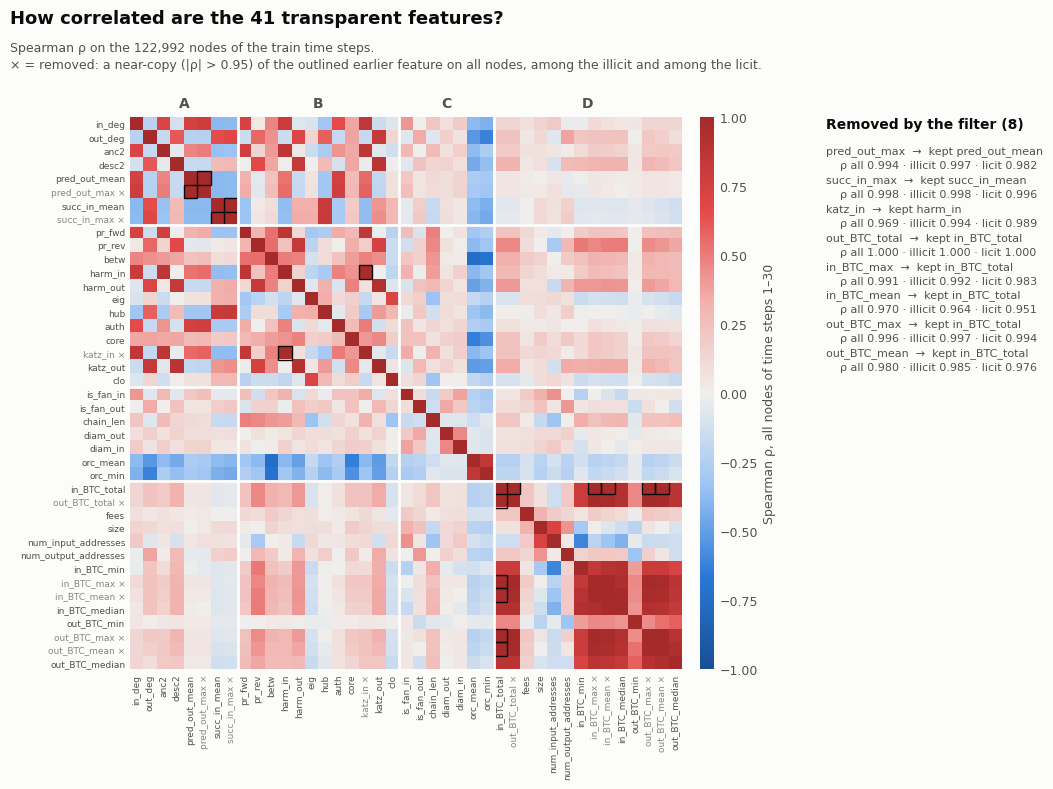

02_corr_transparent.png written (146 KB).


In [ ]:
# Plot 1: the 41 x 41 matrix of the transparent features.
path = PLOTS['02_corr_transparent.png']
if not already_done(path):
    cols = transparent_all
    rho = RHO_TRANSPARENT['all'].reindex(index=cols, columns=cols).fillna(0).to_numpy()
    removed = {r['column']: r for r in REDUNDANT}
    pairs = [(cols.index(r['column']), cols.index(r['kept_partner'])) for r in REDUNDANT]

    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_axes([0.12, 0.15, 0.46, 0.69])   # square: 0.46 x 12 = 0.69 x 8 inches
    im = heatmap(ax, rho, cols, removed, pairs)
    ax.tick_params(labelsize=6.5)
    # family blocks: a 2-pixel gap in the surface colour and the family name above each block
    start = 0
    for family in ['A', 'B', 'C', 'D']:
        size = sum(FAMILY_OF[c] == family for c in cols)
        if start:
            ax.axhline(start - 0.5, color=SURFACE, linewidth=2)
            ax.axvline(start - 0.5, color=SURFACE, linewidth=2)
        ax.text(start + (size - 1) / 2, -1, family, ha='center', va='bottom', fontsize=10, weight='bold', color=INK_2)
        start += size
    colorbar(fig, im, [0.595, 0.15, 0.012, 0.69], 'Spearman ρ, all nodes of time steps 1–30')

    titles(fig, 'How correlated are the 41 transparent features?',
           f'Spearman ρ on the {len(GROUPS["all"]):,} nodes of the train time steps.\n'
           f'× = removed: a near-copy (|ρ| > {RHO_MAX}) of the outlined earlier feature on all nodes, among the illicit and among the licit.')
    lines = [f'{short(r["column"])}  →  kept {short(r["kept_partner"])}\n'
             f'    ρ all {r["rho_all"]:.3f} · illicit {r["rho_illicit"]:.3f} · licit {r["rho_licit"]:.3f}'
             for r in REDUNDANT]
    if len(lines) > 16:
        lines = lines[:15] + [f'... and {len(lines) - 15} more: see removed_features.csv']
    fig.text(0.70, 0.84, f'Removed by the filter ({len(REDUNDANT)})', fontsize=10, weight='bold', va='top')
    fig.text(0.70, 0.805, '\n'.join(lines) if lines else 'none', fontsize=8, color=INK_2, va='top', linespacing=1.5)
    save_png(fig, path)

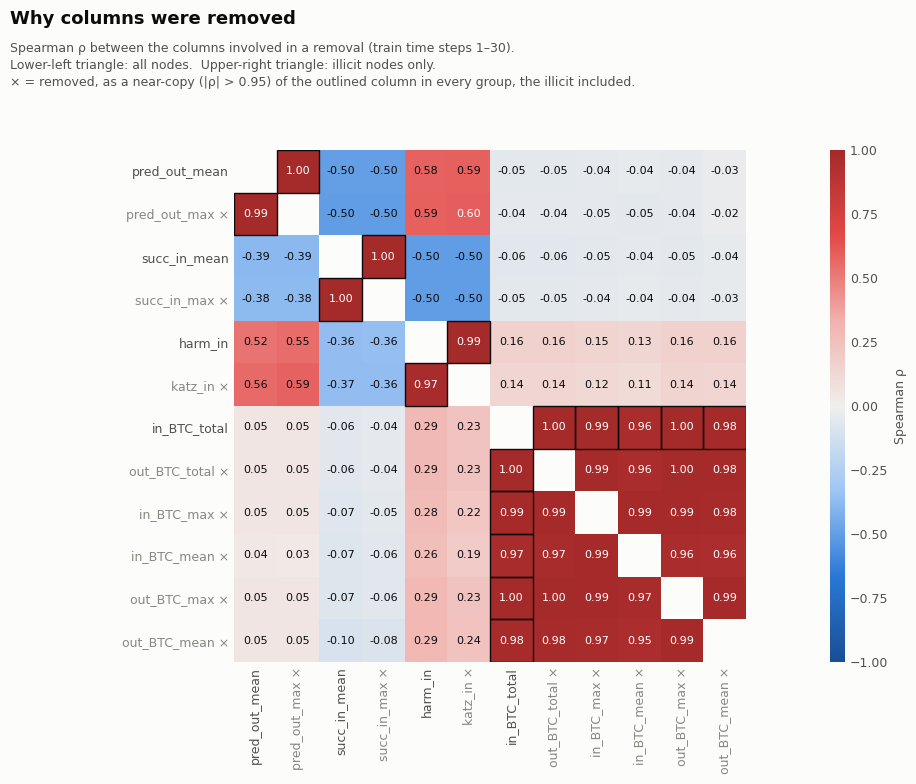

02_corr_removed.png written (112 KB).


In [ ]:
# Plot 2: only the columns involved in a removal; lower triangle = all nodes, upper triangle = illicit nodes.
path = PLOTS['02_corr_removed.png']
involved = [c for c in transparent_all if c in {r['column'] for r in REDUNDANT} | {r['kept_partner'] for r in REDUNDANT}]
if not REDUNDANT:
    print('No column was removed by the redundancy filter: plot skipped.')
elif not already_done(path):
    n_inv = len(involved)
    low = RHO_TRANSPARENT['all'].loc[involved, involved].to_numpy()
    high = RHO_TRANSPARENT['illicit'].loc[involved, involved].to_numpy()
    matrix = np.where(np.tri(n_inv, k=-1, dtype=bool), low, np.where(np.tri(n_inv, k=-1, dtype=bool).T, high, np.nan))
    removed = {r['column'] for r in REDUNDANT}
    pairs = [(involved.index(r['column']), involved.index(r['kept_partner'])) for r in REDUNDANT]

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_axes([0.2, 0.16, 0.6, 0.64])
    im = heatmap(ax, matrix, involved, removed, pairs)
    if n_inv <= 24:   # the values are the point of this plot: write them while they still fit
        size = 8 if n_inv <= 14 else 6.5
        for i in range(n_inv):
            for j in range(n_inv):
                if i != j:
                    v = matrix[i, j]
                    ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=size,
                            color='#ffffff' if abs(v) > 0.6 else INK)
    colorbar(fig, im, [0.84, 0.16, 0.015, 0.64], 'Spearman ρ')
    titles(fig, 'Why columns were removed',
           'Spearman ρ between the columns involved in a removal (train time steps 1–30).\n'
           'Lower-left triangle: all nodes.  Upper-right triangle: illicit nodes only.\n'
           f'× = removed, as a near-copy (|ρ| > {RHO_MAX}) of the outlined column in every group, the illicit included.')
    save_png(fig, path)

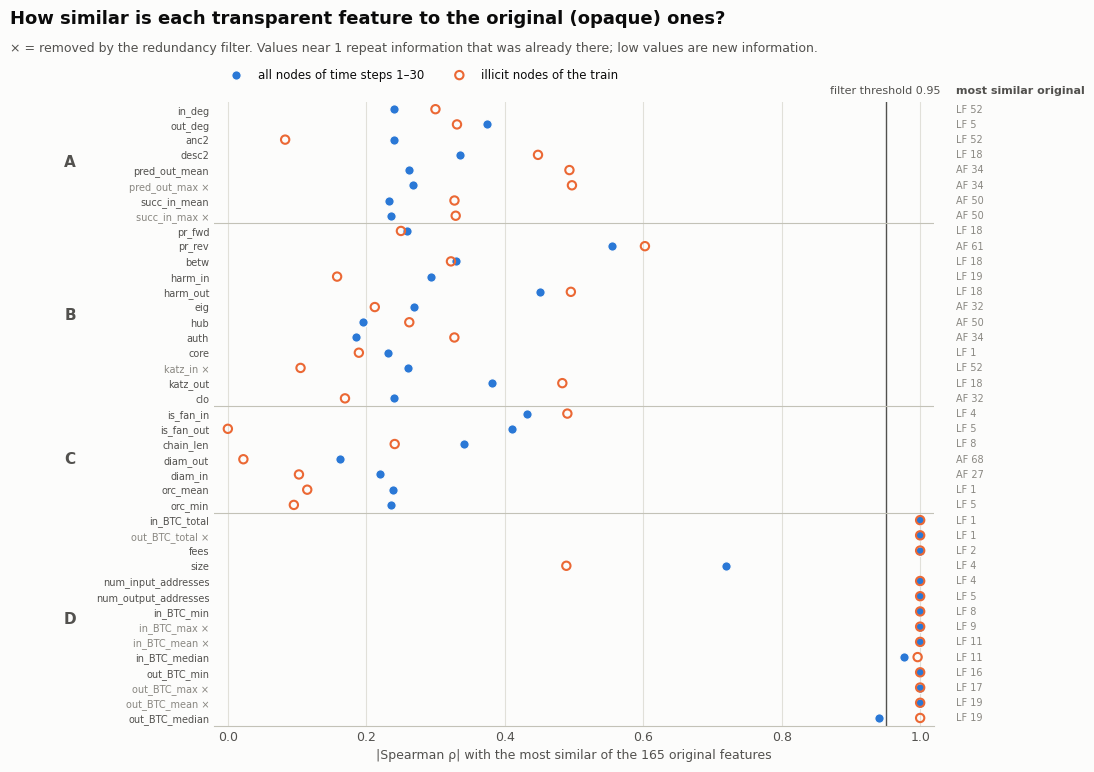

02_corr_transparent_vs_opaque.png written (111 KB).


In [ ]:
# Plot 3: each transparent feature against its most similar original (opaque) feature.
path = PLOTS['02_corr_transparent_vs_opaque.png']
if not already_done(path):
    sim = SIMILARITY
    pos = np.arange(len(sim))
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_axes([0.19, 0.08, 0.6, 0.78])
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(len(sim) - 0.5, -0.5)
    ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.grid(axis='x', color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.axvline(RHO_MAX, color=INK_2, linewidth=1)
    ax.text(RHO_MAX, -0.9, f'filter threshold {RHO_MAX}', ha='center', va='bottom', fontsize=8, color=INK_2)
    ax.scatter(sim['abs_rho_all'], pos, s=48, color=BLUE, edgecolor=SURFACE, linewidth=1, zorder=3,
               label='all nodes of time steps 1–30')
    ax.scatter(sim['abs_rho_illicit'], pos, s=36, facecolors='none', edgecolors=ORANGE, linewidth=1.5, zorder=4,
               label='illicit nodes of the train')
    names = [short(c) + (' ×' if c not in TRANSPARENT_KEPT else '') for c in sim.index]
    ax.set_yticks(pos, names, fontsize=7)
    for tick in ax.get_yticklabels():
        tick.set_color(MUTED if tick.get_text().endswith('×') else INK_2)
    ax.tick_params(length=0)
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.set_xlabel('|Spearman ρ| with the most similar of the 165 original features')
    # family blocks: a hairline between them and the family name on the left
    blend = mtransforms.blended_transform_factory(ax.transAxes, ax.transData)
    start = 0
    for family in ['A', 'B', 'C', 'D']:
        size = int((sim['family'] == family).sum())
        if start:
            ax.axhline(start - 0.5, color=AXIS, linewidth=0.8)
        ax.text(-0.2, start + (size - 1) / 2, family, transform=blend, ha='center', va='center',
                fontsize=11, weight='bold', color=INK_2)
        start += size
    # the most similar original feature of each row, as a text column on the right
    ax.text(1.03, -0.9, 'most similar original', transform=blend, fontsize=8, weight='bold', color=INK_2, va='bottom')
    for p, col in zip(pos, sim.index):
        ax.text(1.03, p, short(sim.loc[col, 'closest_opaque']), transform=blend, fontsize=7, color=MUTED, va='center')
    fig.legend(loc='upper left', bbox_to_anchor=(0.19, 0.915), ncol=2, frameon=False, fontsize=8.5)
    titles(fig, 'How similar is each transparent feature to the original (opaque) ones?',
           '× = removed by the redundancy filter. Values near 1 repeat information that was already there; '
           'low values are new information.')
    save_png(fig, path)

## 9. Feature audit and transformations

For every one of the 206 features, on the nodes of the train time steps (for D only the nodes with the Elliptic++ data, so that the filled medians do not count):
- the distribution: minimum, maximum, quantiles, mean, standard deviation, skewness, share of zeros, number of distinct values;
- the **univariate ROC-AUC** on the evaluation rows of the train: the probability that a random illicit transaction has a higher value than a random licit one. 0.5 = no signal; below 0.5 = higher values point to licit. It is computed from ranks: $\mathrm{AUC} = \frac{R_+ - n_+(n_+ + 1)/2}{n_+ n_-}$, with $R_+$ the sum of the ranks of the illicit rows;
- the transformation of the profile `scaled` (rule of section 0), with its $\mu$ and $\sigma$ on all nodes of the time steps 1–30.

After choosing, the notebook applies every transformation and checks that the train columns have mean 0 and standard deviation 1, and that no value becomes infinite.

In [ ]:
def roc_auc(score, y):
    ranks = pd.Series(score).rank().to_numpy()
    n_pos, n_neg = y.sum(), len(y) - y.sum()
    return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


train_eval = np.flatnonzero(IN_TRAIN & IN_EVAL)
y_train_eval = IS_ILLICIT[train_eval].astype(int)
removed_scope = {r['column']: r['scope'] for r in removed_rows}
audit_rows, SCALED = [], {}
for col in ALL_FEATURES:
    values = features[col].to_numpy(np.float64)
    stats_rows = TRAIN_ECON if FAMILY_OF[col] == 'D' else TRAIN_ROWS
    v = values[stats_rows]
    transform, reason = choose_transform(v)
    mean, std = fit_scaler(values[TRAIN_ROWS], transform)
    if std == 0:   # only a constant column (already removed from every menu) can get here
        assert col in CONSTANT, f'{col}: zero standard deviation'
        std = 1.0
    SCALED[col] = {'transform': transform, 'mean': mean, 'std': std, 'reason': reason}
    q = np.quantile(v, [0, 0.01, 0.25, 0.5, 0.75, 0.99, 1])
    audit_rows.append({
        'feature': col, 'family': FAMILY_OF[col], 'removed_from': removed_scope.get(col, ''),
        'n_rows': len(v), 'n_unique': len(np.unique(v)), 'share_zero': float(np.mean(v == 0)),
        'min': q[0], 'q01': q[1], 'q25': q[2], 'median': q[3], 'q75': q[4], 'q99': q[5], 'max': q[6],
        'mean': float(v.mean()), 'std': float(v.std()), 'skew': float(pd.Series(v).skew()),
        'auc_illicit': roc_auc(values[train_eval], y_train_eval),
        'transform_scaled': transform, 'scaled_mean': mean, 'scaled_std': std,
    })
AUDIT = pd.DataFrame(audit_rows)

# check: every transformation is finite everywhere and standardizes the train columns
for col, spec in SCALED.items():
    z = scale(features[col].to_numpy(np.float64), spec)
    assert np.isfinite(z).all(), f'{col}: infinite values after the transformation'
    if spec['transform'] != 'binary' and col not in CONSTANT:
        assert abs(z[TRAIN_ROWS].mean()) < 1e-6 and abs(z[TRAIN_ROWS].std() - 1) < 1e-6, col

display(AUDIT.groupby(['family', 'transform_scaled']).size().unstack(fill_value=0))
if not already_done(OUTPUTS['feature_audit.csv']):
    write_csv(AUDIT, OUTPUTS['feature_audit.csv'])
    print(f'feature_audit.csv written ({len(AUDIT)} rows).')

transform_scaled,binary,log1p+z,signed_log1p+z,z
family,,,,
A,0,8,0,0
AF,0,0,37,35
B,0,11,0,1
C,2,3,0,2
D,0,14,0,0
LF,0,0,61,32


feature_audit.csv written (206 rows).


In [ ]:
# The transformation of a few columns, written as it will appear in config.json.
for col in ['in_deg', 'katz_in', 'betw', 'is_fan_in', 'orc_mean', 'in_BTC_total', 'Local_feature_1']:
    s = SCALED[col]
    print(f"{col:16s} profile scaled (LogReg, MLP, GNN): {s['transform']:15s} "
          f"mu = {s['mean']:.4g}, sigma = {s['std']:.4g}  ({s['reason']})")

in_deg           profile scaled (LogReg, MLP, GNN): log1p+z         mu = 0.6002, sigma = 0.4617  (never negative, skewness 30.7 > 2: log(1 + x), then z-score)
katz_in          profile scaled (LogReg, MLP, GNN): log1p+z         mu = 0.6249, sigma = 1.112  (never negative, skewness 136.0 > 2: log(1 + x), then z-score)
betw             profile scaled (LogReg, MLP, GNN): log1p+z         mu = 0.003962, sigma = 0.01419  (never negative, skewness 11.0 > 2: log(1 + x), then z-score)
is_fan_in        profile scaled (LogReg, MLP, GNN): binary          mu = 0, sigma = 1  (only the values 0 and 1: unchanged)
orc_mean         profile scaled (LogReg, MLP, GNN): z               mu = 0.03109, sigma = 0.2397  (skewness 0.3: z-score only)
in_BTC_total     profile scaled (LogReg, MLP, GNN): log1p+z         mu = 1.313, sigma = 1.663  (never negative, skewness 19.8 > 2: log(1 + x), then z-score)
Local_feature_1  profile scaled (LogReg, MLP, GNN): signed_log1p+z  mu = -0.04659, sigma = 0.3148  (negative val

## 10. Complete dataset and edges

`dataset.parquet` holds every transaction, in the order of `txs_features.csv`: the six service columns and the **raw** values of all 206 features (also the removed ones: the menus decide what a model sees), as 32-bit floats. The only change to the raw values is the median filled into the D columns of the 965 rows without Elliptic++ data. The transformations are **not** applied here: steps 03 and 04 apply them from `config.json`.

`edges.parquet` holds the edges as row numbers of the dataset, in the direction of the money (`src_row` pays `dst_row`), with their time step. The two ends of an edge always have the same time step: the check below confirms it. The training steps make the graph undirected.

In [ ]:
service = pd.DataFrame({'txId': TXID, 'time_step': STEP.astype(np.int8), 'split': SPLIT, 'y': Y.array,
                        'in_eval': IN_EVAL, 'has_econ': HAS_ECON})
dataset = pd.concat([service, features.astype(np.float32)], axis=1)
assert list(dataset.columns) == SERVICE_COLUMNS + ALL_FEATURES and len(dataset) == N

row_of = pd.Index(TXID)
src, dst = row_of.get_indexer(edge_list.iloc[:, 0]), row_of.get_indexer(edge_list.iloc[:, 1])
assert (src >= 0).all() and (dst >= 0).all(), 'an edge points to an unknown transaction'
assert (STEP[src] == STEP[dst]).all(), 'an edge links two time steps'
edges = pd.DataFrame({'src_row': src.astype(np.int32), 'dst_row': dst.astype(np.int32),
                      'time_step': STEP[src].astype(np.int8)})

for name, df in [('dataset.parquet', dataset), ('edges.parquet', edges)]:
    if not already_done(OUTPUTS[name]):
        start = time.time()
        write_parquet(df, OUTPUTS[name])
        print(f'{name} written: {len(df):,} rows x {df.shape[1]} columns, '
              f'{OUTPUTS[name].stat().st_size / 1e6:.0f} MB, in {fmt_time(time.time() - start)}.')

dataset.parquet written: 203,769 rows x 212 columns, 76 MB, in 3.8s.
edges.parquet written: 234,355 rows x 3 columns, 2 MB, in 0.3s.


## 11. Configuration file

`config.json` collects every **decision** the later steps need, so that tuning (03), final runs (04) and plots (05) all read the same values. It holds no result: results live in the folders of those steps.

| Section | Content |
|---|---|
| `version`, `created` | steps 03 and 04 write in their results which version they used |
| `files` | paths (relative to `DATA_PATH`) and expected sizes of the dataset and the edges |
| `columns` | service columns (never features) and the columns of each family, all and kept |
| `menus` | for each menu: id, description, columns, models |
| `filters` | exact copies, constant columns, redundancy filter, transparent-vs-opaque filter, imputation of D |
| `split` | time steps, rule of the evaluation rows, counts |
| `labels` | classes, positive class, `pos_weight`, prevalence |
| `seeds` | the tuning seed and the three seeds of the final runs |
| `models` | for each model: menus, runtime, transformation profile, fixed hyper-parameters, search space, trials |
| `pairs` | the 44 (menu, model) pairs of the tuning |
| `training` | common settings of the neural models |
| `tuning` | sampler, pruner, objective, resume rules |
| `final_runs` | what step 04 saves for each (menu, model, seed) |
| `evaluation` | thresholds, top-k, bootstrap |
| `transforms` | the profiles and, for each column, the transformation with its $\mu$ and $\sigma$ |
| `plots` | the plots of this step |

**Search spaces.** Each hyper-parameter is `categorical` (a list of `choices`), `float` or `int` (from `low` to `high`, on a log scale if `log` is true), in the format of Optuna. The GNN variants come from Ferretti, D'Angelo and Ghini (2025): `base` = the last convolution gives the output; `lin` = a linear layer after the convolutions; `skip` = like `lin`, with the output of the first convolution added to the last one. For GATv2 the hidden width is heads × width per head. ChebNet uses $K \ge 2$, because with $K = 1$ it does not use the edges.

In [ ]:
FEATURE_MENUS = ['local', 'local_agg', 'graph', 'econ', 'transparent', 'local_agg_graph']
cat = lambda *choices: {'type': 'categorical', 'choices': list(choices)}
real = lambda low, high, log=False: {'type': 'float', 'low': low, 'high': high, 'log': log}
integer = lambda low, high, log=False: {'type': 'int', 'low': low, 'high': high, 'log': log}
NEURAL_COMMON = {'dropout': real(0.0, 0.6), 'lr': real(1e-4, 1e-2, log=True), 'weight_decay': real(1e-6, 1e-2, log=True)}
VARIANT = cat('base', 'lin', 'skip')
WIDTH = cat(32, 64, 128, 256)
SCALED_MODELS = ['logreg', 'mlp', 'sage', 'gatv2', 'cheb', 'gin']

MODELS = {
    'logreg': {'name': 'Logistic Regression (scikit-learn)', 'menus': FEATURE_MENUS, 'runtime': 'cpu', 'profile': 'scaled',
               'fixed': {'penalty': 'l2', 'solver': 'lbfgs', 'max_iter': 5000},
               'space': {'C': cat(*[float(f'{c:.6g}') for c in np.logspace(-4, 2, 10)]),
                         'class_weight': cat(None, 'balanced')},
               'sampler': 'grid', 'trials': {'default': 20},
               'deterministic': True, 'note': 'convex problem and deterministic solver: one final training serves the three seeds'},
    'rf': {'name': 'Random Forest (scikit-learn)', 'menus': FEATURE_MENUS, 'runtime': 'cpu', 'profile': 'raw',
           'fixed': {'n_estimators': 500, 'n_jobs': -1, 'oob_score_in_final_runs': True},
           'space': {'max_features': cat('sqrt', 0.1, 0.2, 0.33, 0.5), 'min_samples_leaf': cat(1, 2, 5, 10, 20),
                     'max_depth': cat(None, 10, 20), 'class_weight': cat(None, 'balanced_subsample')},
           'trials': {'default': 20}},
    'xgb': {'name': 'XGBoost', 'menus': FEATURE_MENUS, 'runtime': 'gpu', 'profile': 'raw',
            'fixed': {'n_estimators': 2000, 'early_stopping_rounds': 100, 'tree_method': 'hist', 'eval_metric': 'aucpr',
                      'device': 'cuda'},
            'space': {'learning_rate': real(0.01, 0.3, log=True), 'max_depth': integer(3, 10),
                      'min_child_weight': real(1, 20, log=True), 'subsample': real(0.5, 1.0),
                      'colsample_bytree': real(0.3, 1.0), 'reg_lambda': real(1e-3, 10, log=True), 'gamma': real(0.0, 5.0),
                      'scale_pos_weight': cat(1.0, round(float(POS_WEIGHT), 6))},
            'trials': {'default': 40}},
    'mlp': {'name': 'MLP (PyTorch)', 'menus': FEATURE_MENUS, 'runtime': 'gpu', 'profile': 'scaled',
            'space': {'layers': cat(1, 2, 3), 'hidden': WIDTH, **NEURAL_COMMON}, 'trials': {'default': 40}},
    'sage': {'name': 'GraphSAGE (PyG SAGEConv)', 'menus': FEATURE_MENUS, 'runtime': 'gpu', 'profile': 'scaled',
             'space': {'layers': cat(2, 3), 'hidden': WIDTH, 'aggr': cat('mean', 'max'), 'variant': VARIANT, **NEURAL_COMMON},
             'trials': {'default': 40}},
    'gatv2': {'name': 'GATv2 (PyG GATv2Conv)', 'menus': FEATURE_MENUS, 'runtime': 'gpu', 'profile': 'scaled',
              'space': {'layers': cat(2, 3), 'heads': cat(1, 2, 4, 8), 'hidden_per_head': cat(16, 32, 64), 'variant': VARIANT,
                        **NEURAL_COMMON, 'att_dropout': real(0.0, 0.6)},
              'trials': {'default': 40}},
    'cheb': {'name': 'ChebNet (PyG ChebConv)', 'menus': FEATURE_MENUS + ['none'], 'runtime': 'gpu', 'profile': 'scaled',
             'fixed': {'normalization': 'sym'},
             'space': {'K': cat(2, 3, 4), 'layers': cat(2, 3), 'hidden': WIDTH, 'variant': VARIANT, **NEURAL_COMMON},
             'trials': {'default': 40, 'none': 20}},
    'gin': {'name': 'GIN (PyG GINConv)', 'menus': ['none'], 'runtime': 'gpu', 'profile': 'scaled',
            'space': {'layers': cat(2, 3, 4, 5), 'hidden': cat(32, 64, 128), 'train_eps': cat(False, True),
                      'jumping_knowledge': cat(None, 'max', 'cat'), 'dropout': real(0.0, 0.5),
                      'lr': real(1e-4, 1e-2, log=True), 'weight_decay': real(1e-6, 1e-2, log=True)},
            'trials': {'default': 20}},
}
assert len(MODELS['logreg']['space']['C']['choices']) * 2 == MODELS['logreg']['trials']['default']
PAIRS = [[menu, model] for model, spec in MODELS.items() for menu in spec['menus']]
assert len(PAIRS) == 44
for key, menu in MENUS.items():
    menu['models'] = [model for model, spec in MODELS.items() if key in spec['menus']]
n_trials = sum(spec['trials'].get(menu, spec['trials']['default']) for model, spec in MODELS.items() for menu in spec['menus'])
print(f'{len(PAIRS)} pairs, {len(PAIRS) * len(FINAL_SEEDS)} final triples, {n_trials:,} tuning trials.')

44 pairs, 132 final triples, 1,480 tuning trials.


In [ ]:
n_test = int(counts.loc['test', 'eval_rows'])
prevalence = {split: float(counts.loc[split, 'prevalence']) for split in ['train', 'val', 'test']}
split_info = {split: {'time_steps': [steps.start, steps.stop - 1], **{k: int(counts.loc[split, k]) for k in
                      ['nodes', 'labeled', 'eval_rows', 'illicit', 'licit']}, 'prevalence': prevalence[split]}
              for split, steps in [('train', TRAIN_STEPS), ('val', VAL_STEPS), ('test', TEST_STEPS)]}

config = {
    'version': CONFIG_VERSION,
    'created': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'files': {'dataset': '02-feature-menus/dataset.parquet', 'edges': '02-feature-menus/edges.parquet',
              'feature_audit': '02-feature-menus/feature_audit.csv', 'removed_features': '02-feature-menus/removed_features.csv',
              'n_rows': N, 'n_edges': len(edges), 'row_order': 'the order of txs_features.csv; row number = node id'},
    'columns': {
        'service': SERVICE_COLUMNS,
        'service_meaning': {'txId': 'transaction id', 'time_step': '1-49, never a feature', 'split': 'train / val / test',
                            'y': '1 illicit, 0 licit, null unknown', 'in_eval': 'enters loss and metrics',
                            'has_econ': 'has the Elliptic++ data (else D is the train median)'},
        'families': {f: {'all': cols, 'kept': [c for c in cols if c not in CONSTANT and
                                               (FAMILY_OF[c] in ('LF', 'AF') or c in TRANSPARENT_KEPT)]}
                     for f, cols in FAMILIES.items()},
        'opaque': ['LF', 'AF'], 'transparent': ['A', 'B', 'C', 'D'],
    },
    'menus': MENUS,
    'filters': {
        'exact_copies': [{'column': c, 'copy_of': k, 'action': 'not in the dataset'} for c, k in D_COPIES.items()],
        'constant': CONSTANT,
        'redundancy': {
            'columns': 'the 41 transparent features', 'method': 'Spearman rho', 'threshold': RHO_MAX,
            'groups': {'all': f'every node of time steps 1-30 with the Elliptic++ data ({len(GROUPS["all"])} rows)',
                       'illicit': f'evaluation rows of time steps 1-30, illicit ({len(GROUPS["illicit"])})',
                       'licit': f'evaluation rows of time steps 1-30, licit ({len(GROUPS["licit"])})'},
            'rule': 'visit the columns in `order`; remove a column if |rho| > threshold with an already kept column '
                    'in every group (all, illicit and licit)',
            'order': TRANSPARENT, 'removed': REDUNDANT},
        'transparent_vs_opaque': {
            'menu': 'local_agg_graph', 'transparent_columns': GRAPH_KEPT, 'threshold': RHO_MAX,
            'rule': 'remove from the menu an opaque column with |rho| > threshold with a kept graph feature in every group',
            'removed': OPAQUE_REMOVED},
        'imputation': {'columns': D_COLUMNS, 'rows': int((~HAS_ECON).sum()),
                       'labeled_rows': int((Y.notna().to_numpy() & ~HAS_ECON).sum()),
                       'value': 'median of the nodes of time steps 1-30 with the Elliptic++ data',
                       'medians': {c: float(v) for c, v in D_MEDIANS.items()}},
    },
    'split': {**split_info, 'eval_rule': 'labeled (illicit or licit) and has_econ'},
    'labels': {'positive_class': 'illicit', 'y': {'1': 'illicit', '0': 'licit', 'null': 'unknown'},
               'class_codes_in_txs_classes': {'1': 'illicit', '2': 'licit', '3': 'unknown'},
               'unknown': 'stay in the graph, never in loss or metrics', 'pos_weight': float(POS_WEIGHT),
               'pos_weight_rule': 'licit / illicit among the evaluation rows of the train', 'prevalence': prevalence},
    'seeds': {'tuning': TUNING_SEED, 'final': FINAL_SEEDS,
              'rule': 'set_seed(seed) before every tuning trial (always the tuning seed) and before every final run; '
                      'random_state = seed in scikit-learn and XGBoost'},
    'models': MODELS,
    'pairs': PAIRS,
    'training': {
        'models': ['mlp', 'sage', 'gatv2', 'cheb', 'gin'], 'optimizer': 'adam', 'batch': 'full',
        'loss': 'binary cross-entropy with logits, pos_weight of labels', 'loss_rows': 'in_eval rows of the period',
        'max_epochs': 1000, 'max_epochs_if_capped': 2000,
        'capped_rule': 'if the best trial of a pair stops at max_epochs, that pair is tuned again with max_epochs_if_capped',
        'patience': {'mlp': 50, 'gnn': 100}, 'early_stopping_metric': 'validation average precision',
        'graph': {'undirected': True, 'periods': {s: split_info[s]['time_steps'] for s in split_info},
                  'rule': 'each split has its own graph: the nodes of its time steps (unknown included) and the edges '
                          'among them; GNNs train on the train graph and are evaluated on the val and test graphs'},
        'none_menu_input': 'x = 1 for every node',
    },
    'tuning': {
        'library': 'optuna', 'objective': 'validation average precision (PR-AUC)', 'direction': 'maximize',
        'sampler': {'name': 'TPESampler', 'seed': TUNING_SEED, 'n_startup_trials': 10,
                    'resume_seed': 'seed + number of finished trials'},
        'pruner': {'name': 'MedianPruner', 'n_startup_trials': 5, 'n_warmup_steps': 50, 'models': 'neural models'},
        'budget_counts': ['COMPLETE', 'PRUNED'], 'failed_trials': 'recorded as FAIL (for example out of GPU memory), not counted',
        'storage': 'SQLite on the Colab disk, copied to Drive at most every 60 s and at the end of each pair',
        'train_average_precision': False, 'test_set': 'never read',
    },
    'final_runs': {
        'seeds': FINAL_SEEDS, 'determinism_check': 'first triple of each GPU model trained twice with the same seed',
        'train_average_precision_every': 10,
        'save': {'predictions': 'score of every evaluation row of train, val and test',
                 'summary': 'hyper-parameters, best epoch or iteration, time, GPU memory, parameters, versions, main metrics',
                 'curves': 'per epoch (neural) or per tree (XGBoost)', 'importances': 'LogReg coefficients, RF and XGBoost',
                 'model': 'state_dict .pt (neural), .json (XGBoost), compressed joblib (LogReg, RF), every seed',
                 'embeddings': 'not saved: recomputed from the weights when needed'},
    },
    'evaluation': {
        'primary_metric': 'average precision (PR-AUC)',
        'thresholds': ['0.5', 'the threshold with the best illicit F1 on validation'],
        'metrics': ['average_precision', 'roc_auc', 'tp', 'fp', 'tn', 'fn', 'precision', 'recall', 'f1 (both classes)',
                    'f1_macro', 'mcc'],
        'top_k': {'0.1% of test': round(0.001 * n_test), '1% of test': round(0.01 * n_test),
                  '10% of test': round(0.1 * n_test), 'train prevalence x test': round(prevalence['train'] * n_test),
                  '100': 100, 'illicit in test': int(counts.loc['test', 'illicit'])},
        'bootstrap': {'resamples': 1000, 'replace': True, 'interval': [2.5, 97.5], 'seed': 0},
    },
    'transforms': {
        'rule': f'binary: unchanged; never negative and skewness > {SKEW_MAX:g}: log(1 + x) then z-score; negative '
                f'values and |skewness| > {SKEW_MAX:g}: sign(x) log(1 + |x|) then z-score; otherwise z-score',
        'decided_on': 'nodes of time steps 1-30 (for D only those with the Elliptic++ data)',
        'z_score_on': 'every node of time steps 1-30, unknown included; the same mean and std for val and test',
        'apply': 'z = (sign(x) log(1 + |x|) - mean) / std for the two log transforms, (x - mean) / std for z, x for binary',
        'profiles': {
            'raw': {'models': ['rf', 'xgb'], 'description': 'no transformation: trees only use the order of the values'},
            'scaled': {'models': SCALED_MODELS,
                       'columns': {c: {**s, 'text': f"{c}, profile scaled (used by {', '.join(SCALED_MODELS)}): "
                                                    f"{s['transform']} (mean {s['mean']:.6g}, std {s['std']:.6g})"}
                                   for c, s in SCALED.items()}},
        },
    },
    'plots': {name: f'plots/{name}' for name in PLOTS},
}
assert set(config['menus']) == {'local', 'local_agg', 'graph', 'econ', 'transparent', 'local_agg_graph', 'none'}
if not already_done(OUTPUTS['config.json']):
    write_json(config, OUTPUTS['config.json'])
    print(f"config.json written ({OUTPUTS['config.json'].stat().st_size / 1e3:.0f} KB).")

config.json written (116 KB).


## 12. Final check and Drive sync

Reads every output back from Drive and checks it against what this run computed. The last cell makes sure that every file has been uploaded to Drive.

In [ ]:
check = pd.read_parquet(OUTPUTS['dataset.parquet'])
assert list(check.columns) == SERVICE_COLUMNS + ALL_FEATURES and len(check) == N
assert (check['txId'].to_numpy() == TXID).all() and (check['in_eval'].to_numpy() == IN_EVAL).all()
assert all(check[c].dtype == np.float32 for c in ALL_FEATURES) and not check[ALL_FEATURES].isna().any().any()
check_edges = pd.read_parquet(OUTPUTS['edges.parquet'])
assert len(check_edges) == 234_355 and check_edges['src_row'].max() < N and check_edges['dst_row'].max() < N

saved = json.loads(OUTPUTS['config.json'].read_text(encoding='utf-8'))
assert len(saved['pairs']) == 44 and saved['split']['test']['illicit'] == 524
for key, menu in saved['menus'].items():
    assert set(menu['columns']) <= set(ALL_FEATURES) and (menu['n_columns'] > 0) == (key != 'none'), key
assert len(pd.read_csv(OUTPUTS['feature_audit.csv'])) == len(ALL_FEATURES)
assert len(pd.read_csv(OUTPUTS['removed_features.csv'])) >= len(D_COPIES)
for name, path in PLOTS.items():
    if path.exists():
        with Image.open(path) as image:
            assert image.size[0] <= MAX_PIXELS[0] and image.size[1] <= MAX_PIXELS[1], name
        assert path.stat().st_size <= MAX_KB * 1000, name
print({key: menu['n_columns'] for key, menu in saved['menus'].items()})
print('Every output is complete.')

{'local': 93, 'local_agg': 165, 'graph': 24, 'econ': 9, 'transparent': 33, 'local_agg_graph': 189, 'none': 0}
Every output is complete.


In [ ]:
drive.flush_and_unmount()
print('Every file is on Drive in', OUT_DIR, 'and', PLOT_DIR)

Every file is on Drive in /content/drive/MyDrive/UNIVERSITA/block-crypto/data/02-feature-menus and /content/drive/MyDrive/UNIVERSITA/block-crypto/data/plots
